In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

trial_path = Path("data/AOIs_data.xlsx")

df = pd.read_excel(trial_path)

print(df.shape)
print(df.columns.tolist())
print(df["Dataset_abbreviation"].value_counts())
print(df["score"].value_counts())

(22916, 6)
['TOI', 'ParticipantID', 'Dataset_abbreviation', 'fix_ratio_kz', 'fix_ratio_ra', 'score']
Dataset_abbreviation
SLSO      8345
STT       4789
TMA       4788
STAT-A    3327
STAT-B    1667
Name: count, dtype: int64
score
1    17604
0     5312
Name: count, dtype: int64


In [2]:
# Combine STAT-A and STAT-B into STAT
df["Dataset"] = df["Dataset_abbreviation"].replace({
    "STAT-A": "STAT",
    "STAT-B": "STAT"
})

# The score indicates eye-tracking task accuracy: 0 = incorrect, 1 = correct
df["Accuracy"] = df["score"].map({
    0: "Incorrect",
    1: "Correct"
})

df["Accuracy"] = pd.Categorical(
    df["Accuracy"],
    categories=["Incorrect", "Correct"],
    ordered=True
)

print(df.groupby("Dataset")["TOI"].nunique())

Dataset
SLSO    40
STAT    24
STT     23
TMA     23
Name: TOI, dtype: int64


In [3]:
aoi_metrics = [
    "fix_ratio_kz",
    "fix_ratio_ra"
]

aoi_check = (
    df.groupby("Dataset")[aoi_metrics]
      .agg(["count", "mean", "min", "max"])
)

print(aoi_check)

print("\nNumber of missing values:")
print(df[aoi_metrics].isna().sum())

        fix_ratio_kz                          fix_ratio_ra                 \
               count      mean  min       max        count      mean  min   
Dataset                                                                     
SLSO            8345  0.162025  0.0  0.760000         8345  0.028480  0.0   
STAT            4994  0.124919  0.0  0.692308         4994  0.090299  0.0   
STT             4789  0.255339  0.0  1.000000         4789  0.101620  0.0   
TMA             4788  0.232163  0.0  0.840000         4788  0.087346  0.0   

                   
              max  
Dataset            
SLSO     0.400000  
STAT     0.750000  
STT      0.833333  
TMA      0.666667  

Number of missing values:
fix_ratio_kz    0
fix_ratio_ra    0
dtype: int64


In [4]:
participant_accuracy_mean = (
    df.groupby(
        ["ParticipantID", "Dataset", "Accuracy"],
        observed=True
    )[aoi_metrics]
    .mean()
    .reset_index()
)

participant_accuracy_mean.head()

,ParticipantID,Dataset,Accuracy,fix_ratio_kz,fix_ratio_ra
0,P001,SLSO,Incorrect,0.171497,0.021103
1,P001,SLSO,Correct,0.168632,0.026400
2,P001,STAT,Incorrect,0.238889,0.044697
3,P001,STAT,Correct,0.147600,0.082587
4,P001,STT,Incorrect,0.352584,0.067049


In [5]:
def descriptive_statistics(data, group_columns, metrics):
    rows = []

    for groups, group_data in data.groupby(
        group_columns,
        observed=True
    ):
        if not isinstance(groups, tuple):
            groups = (groups,)

        group_info = dict(zip(group_columns, groups))

        for metric in metrics:
            values = group_data[metric].dropna()

            rows.append({
                **group_info,
                "Metric": metric,
                "N": len(values),
                "Mean": values.mean(),
                "SD": values.std(ddof=1),
                "Median": values.median(),
                "Q1": values.quantile(0.25),
                "Q3": values.quantile(0.75)
            })

    return pd.DataFrame(rows)

In [6]:
accuracy_descriptives = descriptive_statistics(
    data=participant_accuracy_mean,
    group_columns=["Dataset", "Accuracy"],
    metrics=aoi_metrics
)

accuracy_descriptives

,Dataset,Accuracy,Metric,N,Mean,SD,Median,Q1,Q3
0,SLSO,Incorrect,fix_ratio_kz,210,0.124849,0.042035,0.121493,0.102541,0.153769
1,SLSO,Incorrect,fix_ratio_ra,210,0.017342,0.010477,0.016107,0.010553,0.022505
2,SLSO,Correct,fix_ratio_kz,209,0.171493,0.043315,0.175210,0.143457,0.201752
3,SLSO,Correct,fix_ratio_ra,209,0.031477,0.013273,0.030996,0.022989,0.039313
4,STAT,Incorrect,fix_ratio_kz,210,0.145840,0.080447,0.139215,0.095999,0.193685
5,STAT,Incorrect,fix_ratio_ra,210,0.047169,0.029370,0.041661,0.027659,0.061456
6,STAT,Correct,fix_ratio_kz,210,0.118318,0.029298,0.118131,0.100963,0.138084
7,STAT,Correct,fix_ratio_ra,210,0.102987,0.018833,0.101471,0.092950,0.113188
8,STT,Incorrect,fix_ratio_kz,210,0.320293,0.052205,0.318729,0.285359,0.355034
9,STT,Incorrect,fix_ratio_ra,210,0.087787,0.032663,0.083466,0.066857,0.107073


In [7]:
def holm_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    n_tests = len(p_values)

    order = np.argsort(p_values)
    adjusted = np.empty(n_tests)

    previous = 0

    for rank, index in enumerate(order):
        adjusted_p = (n_tests - rank) * p_values[index]
        adjusted_p = min(adjusted_p, 1.0)

        # Ensure adjusted p-values are monotonically increasing
        adjusted_p = max(adjusted_p, previous)
        adjusted[index] = adjusted_p
        previous = adjusted_p

    return adjusted

In [8]:
def paired_aoi_tests(data, metrics):
    results = []

    for dataset in ["STAT", "TMA", "SLSO",'STT']:
        subset = data[data["Dataset"] == dataset]

        for metric in metrics:
            wide = subset.pivot(
                index="ParticipantID",
                columns="Accuracy",
                values=metric
            )

            # Retain participants with both correct and incorrect trials
            wide = wide[["Incorrect", "Correct"]].dropna()

            incorrect = wide["Incorrect"]
            correct = wide["Correct"]
            difference = correct - incorrect

            # Paired-samples t-test
            t_result = stats.ttest_rel(
                correct,
                incorrect,
                nan_policy="omit"
            )

            # Wilcoxon signed-rank test
            wilcoxon_result = stats.wilcoxon(
                correct,
                incorrect,
                zero_method="wilcox"
            )

            n = len(difference)
            mean_difference = difference.mean()
            sd_difference = difference.std(ddof=1)
            se_difference = sd_difference / np.sqrt(n)

            critical_t = stats.t.ppf(
                0.975,
                df=n - 1
            )

            ci_lower = (
                mean_difference -
                critical_t * se_difference
            )

            ci_upper = (
                mean_difference +
                critical_t * se_difference
            )

            cohens_dz = (
                mean_difference / sd_difference
                if sd_difference != 0 else np.nan
            )

            results.append({
                "Dataset": dataset,
                "Metric": metric,
                "Paired_N": n,
                "Incorrect_Mean": incorrect.mean(),
                "Incorrect_SD": incorrect.std(ddof=1),
                "Correct_Mean": correct.mean(),
                "Correct_SD": correct.std(ddof=1),
                "Mean_Difference_Correct_Minus_Incorrect":
                    mean_difference,
                "CI_95_Lower": ci_lower,
                "CI_95_Upper": ci_upper,
                "t": t_result.statistic,
                "df": n - 1,
                "p_t_test": t_result.pvalue,
                "Cohens_dz": cohens_dz,
                "Wilcoxon_W": wilcoxon_result.statistic,
                "p_Wilcoxon": wilcoxon_result.pvalue
            })

    results = pd.DataFrame(results)

    # Apply Holm correction to the six within-dataset tests
    results["p_Holm"] = holm_adjust(
        results["p_t_test"]
    )

    return results

In [9]:
accuracy_results = paired_aoi_tests(
    data=participant_accuracy_mean,
    metrics=aoi_metrics
)

print(accuracy_results)

  Dataset        Metric  Paired_N  Incorrect_Mean  Incorrect_SD  Correct_Mean  \
0    STAT  fix_ratio_kz       210        0.145840      0.080447      0.118318   
1    STAT  fix_ratio_ra       210        0.047169      0.029370      0.102987   
2     TMA  fix_ratio_kz       209        0.256912      0.060342      0.221078   
3     TMA  fix_ratio_ra       209        0.063903      0.024410      0.099014   
4    SLSO  fix_ratio_kz       209        0.124539      0.041895      0.171493   
5    SLSO  fix_ratio_ra       209        0.017232      0.010381      0.031477   
6     STT  fix_ratio_kz       210        0.320293      0.052205      0.241523   
7     STT  fix_ratio_ra       210        0.087787      0.032663      0.104244   

   Correct_SD  Mean_Difference_Correct_Minus_Incorrect  CI_95_Lower  \
0    0.029298                                -0.027523    -0.039925   
1    0.018833                                 0.055819     0.051183   
2    0.051164                                -0.035834   

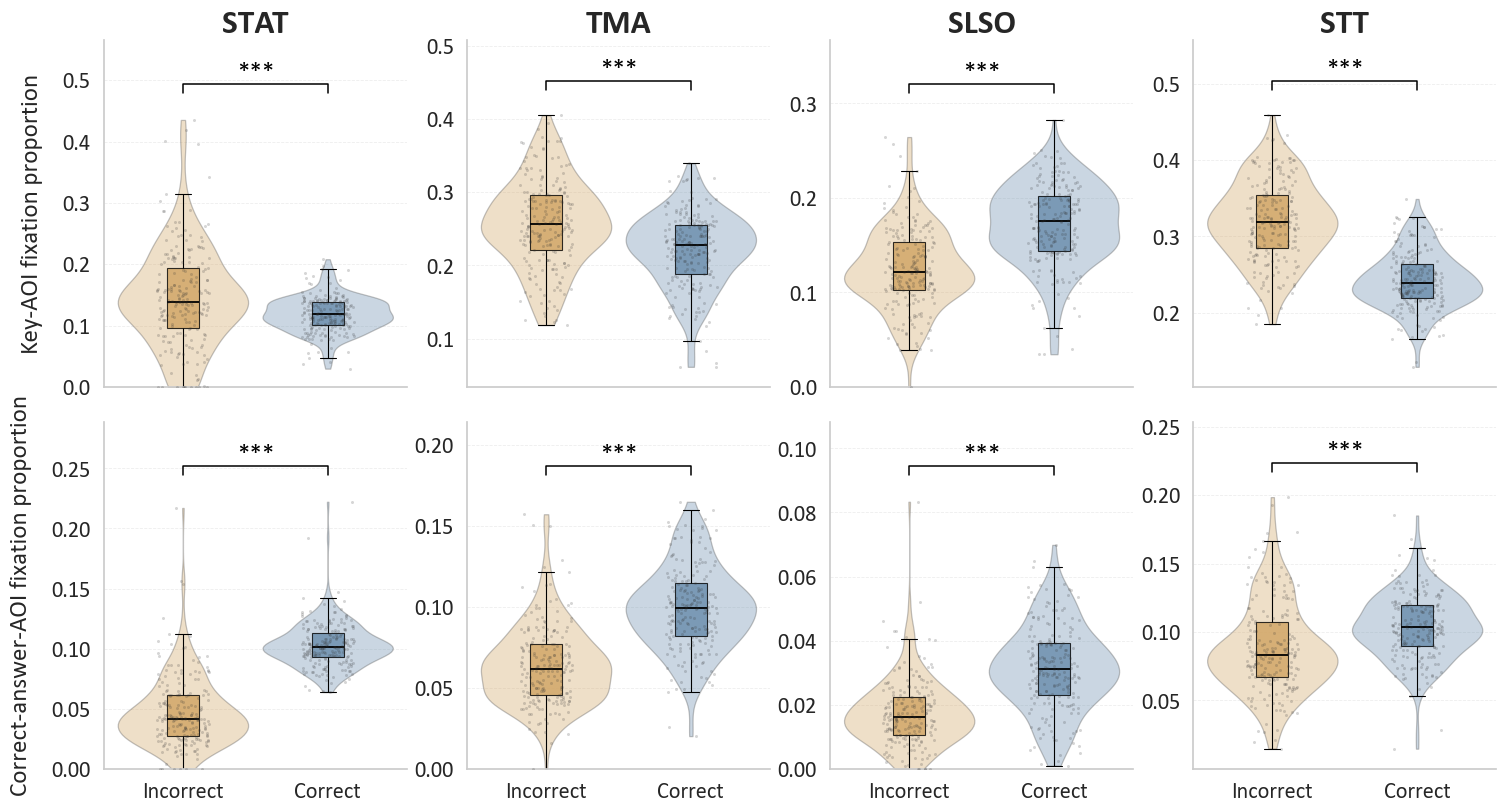

In [11]:
from matplotlib import rcParams

# ============================================================
# 1. Global font and plot style
# ============================================================

rcParams["font.family"] = "Calibri"
rcParams["font.sans-serif"] = ["Calibri"]
rcParams["axes.unicode_minus"] = False

sns.set_theme(
    style="whitegrid",
    font="Calibri",
    font_scale=1.5
)

# ============================================================
# 2. Prepare plotting data
# ============================================================

metric_labels = {
    "fix_ratio_kz": "Key-AOI fixation proportion",
    "fix_ratio_ra": "Correct-answer-AOI fixation proportion"
}

plot_data = participant_accuracy_mean.rename(
    columns=metric_labels
)

plot_data = plot_data.melt(
    id_vars=[
        "ParticipantID",
        "Dataset",
        "Accuracy"
    ],
    value_vars=list(metric_labels.values()),
    var_name="AOI metric",
    value_name="Fixation proportion"
)

dataset_order = ["STAT", "TMA", "SLSO", 'STT']

metric_order = [
    "Key-AOI fixation proportion",
    "Correct-answer-AOI fixation proportion"
]

accuracy_order = ["Incorrect", "Correct"]

palette = {
    "Incorrect": "#E3A84F",
    "Correct": "#5B8DB8"
}

# Ensure test results include readable metric names
accuracy_results["Metric_label"] = (
    accuracy_results["Metric"].map(metric_labels)
)

# ============================================================
# 3. Significance symbol function
# ============================================================

def significance_symbol(p):
    if pd.isna(p):
        return ""
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"


def add_significance_bracket(
    ax,
    x1,
    x2,
    y,
    height,
    label,
    fontsize=14
):


    ax.plot(
        [x1, x1, x2, x2],
        [y, y + height, y + height, y],
        color="black",
        linewidth=1.1,
        clip_on=False
    )

    ax.text(
        (x1 + x2) / 2,
        y + height,
        label,
        ha="center",
        va="bottom",
        fontsize=fontsize,
        fontfamily="Calibri",
        color="black"
    )

# ============================================================
# 4. Create a 2 × 3 comparison plot
# ============================================================

fig, axes = plt.subplots(
    nrows=2,
    ncols=4,
    figsize=(16, 9),
    sharex=True,
    sharey=False
)

for row_index, metric in enumerate(metric_order):

    for col_index, dataset in enumerate(dataset_order):

        ax = axes[row_index, col_index]

        subset = plot_data[
            (plot_data["Dataset"] == dataset) &
            (plot_data["AOI metric"] == metric)
        ].copy()

        # Violin plots show the distributions
        sns.violinplot(
            data=subset,
            x="Accuracy",
            y="Fixation proportion",
            order=accuracy_order,
            palette=palette,
            hue="Accuracy",
            hue_order=accuracy_order,
            legend=False,
            inner=None,
            cut=0,
            density_norm="width",
            width=0.90,
            linewidth=0.9,
            alpha=0.35,
            ax=ax
        )

        # Box plots show medians and quartiles
        sns.boxplot(
            data=subset,
            x="Accuracy",
            y="Fixation proportion",
            order=accuracy_order,
            hue="Accuracy",
            hue_order=accuracy_order,
            palette=palette,
            legend=False,
            width=0.22,
            showfliers=False,
            boxprops={
                "alpha": 0.80,
                "edgecolor": "black",
                "linewidth": 0.8
            },
            whiskerprops={
                "color": "black",
                "linewidth": 0.8
            },
            capprops={
                "color": "black",
                "linewidth": 0.8
            },
            medianprops={
                "color": "black",
                "linewidth": 1.3
            },
            ax=ax
        )

        # Add jittered participant data points
        sns.stripplot(
            data=subset,
            x="Accuracy",
            y="Fixation proportion",
            order=accuracy_order,
            color="#333333",
            alpha=0.20,
            size=2.2,
            jitter=0.18,
            ax=ax
        )

        # ----------------------------------------------------
        # Find the corresponding Holm-adjusted p-value
        # ----------------------------------------------------

        p_row = accuracy_results[
            (accuracy_results["Dataset"] == dataset) &
            (accuracy_results["Metric_label"] == metric)
        ]

        if len(p_row) == 1:
            p_value = p_row["p_Holm"].iloc[0]
        else:
            p_value = np.nan

        # ----------------------------------------------------
        # Add significance markers
        # ----------------------------------------------------

        data_min = subset["Fixation proportion"].min()
        data_max = subset["Fixation proportion"].max()
        data_range = data_max - data_min

        if data_range == 0:
            data_range = 0.01

        # Reserve space at the top for significance brackets
        bracket_y = data_max + data_range * 0.10
        bracket_height = data_range * 0.035
        upper_limit = data_max + data_range * 0.30

        ax.set_ylim(
            max(0, data_min - data_range * 0.08),
            upper_limit
        )

        if not pd.isna(p_value) and p_value < 0.05:
            add_significance_bracket(
                ax=ax,
                x1=0,
                x2=1,
                y=bracket_y,
                height=bracket_height,
                label=significance_symbol(p_value),
                fontsize=18
            )

        # ----------------------------------------------------
        # Format subplots
        # ----------------------------------------------------

        if row_index == 0:
            ax.set_title(
                dataset,
                fontsize=24,
                fontweight="bold",
                pad=5,
                fontfamily="Calibri"
            )
        else:
            ax.set_title("")

        if col_index == 0:
            ax.set_ylabel(
                metric,
                fontsize=18,
                labelpad=14,
                fontfamily="Calibri"
            )
        else:
            ax.set_ylabel("")

        if row_index == 1:
            ax.set_xlabel("")
        else:
            ax.set_xlabel("")

        ax.tick_params(
            axis="both",
            labelsize=16
        )

        # Reduce distractions from borders and gridlines
        ax.grid(
            axis="y",
            linestyle="--",
            linewidth=0.6,
            alpha=0.35
        )

        ax.grid(
            axis="x",
            visible=False
        )

        sns.despine(
            ax=ax,
            top=True,
            right=True
        )

# ============================================================
# 5. Overall layout
# ============================================================

# Leave more space for each subplot
plt.subplots_adjust(
    left=0.11,
    right=0.98,
    top=0.92,
    bottom=0.11,
    wspace=0.2,
    hspace=0.1
)

plt.savefig(
    "correct_incorrect_AOI_comparison.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()